<a href="https://colab.research.google.com/github/caio7197/PetDadosNovaYork/blob/main/codigos/02-analise-de-dados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from google.colab import userdata
import os

USUARIO = "caio7197"
EMAIL = "caioc7197@gmail.com"
REPO = "PetDadosNovaYork"

token = userdata.get("GITHUB_TOKEN")

if not os.path.exists(REPO):
  !git clone https://{token}@github.com/{USUARIO}/{REPO}.git

!git config --global user.name {USUARIO}
!git config --global user.email {EMAIL}

%cd {REPO}

/content/PetDadosNovaYork


In [11]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "AB_NYC_2019.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "dgomonov/new-york-city-airbnb-open-data",
    file_path
)

#informaçoes sobre base de dados dos airbnb
df.info()
print(df.isna().sum())
print(df.duplicated().sum())

#converter tipos
df['last_review']=pd.to_datetime(df['last_review'], errors='coerce')
df['reviews_per_mont']=df['reviews_per_month'].fillna(0)
df['host_name']=df['host_name'].fillna('desconhecido')
df=df.drop_duplicates()

display(df['price'].quantile([0.5,0.9,0.95,0.99]))

q1, q3 = df['price'].quantile([0.25,0.75])
limite=q3+1.5*(q3-q1)

df_limpo=df[(df['price']>0) & (df['price']<=limite)]

df_limpo.to_csv("dados/limpos/dados.limpos.csv")
df.to_csv("dados/brutos/dados.brutos.csv")

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_o

,price
0.50,106.0
0.90,269.0
0.95,355.0
0.99,799.0


[main fa7ab9c] dados brutos e dados limpos
 2 files changed, 95170 insertions(+)
 create mode 100644 dados/brutos/dados.brutos.csv
 create mode 100644 dados/limpos/dados.limpos.csv
Enumerating objects: 11, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 2.48 MiB | 2.33 MiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 1 local object.
To https://github.com/caio7197/PetDadosNovaYork.git
   31b8d5d..fa7ab9c  main -> main


In [14]:
df_limpo.head(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,reviews_per_mont
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365,0.21
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355,0.38
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaT,NaN,1,365,0.00
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194,4.64
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0,0.10


In [19]:
df = df_limpo.copy()
df['neighbourhood_group'].value_counts()

,count
neighbourhood_group,
Manhattan,19505
Brooklyn,19406
Queens,5567
Bronx,1069
Staten Island,365


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


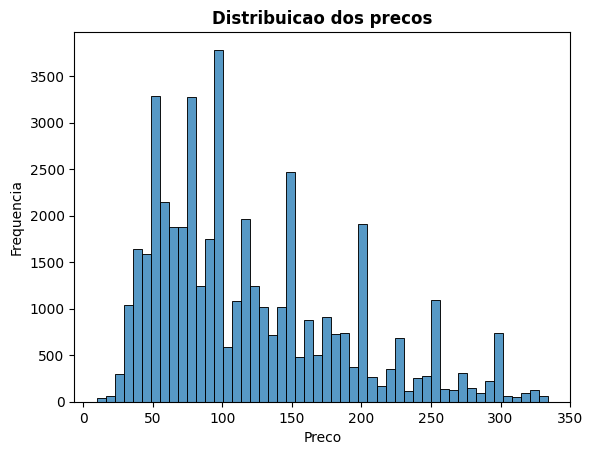

In [23]:
sns.histplot(data=df, x ='price', bins=50)
plt.title('Distribuicao dos precos', fontweight='bold', fontsize=12)

plt.xlabel('Preco')
plt.ylabel('Frequencia')

plt.show()

In [27]:
df.groupby('neighbourhood_group')['price'].agg(['mean','median']).sort_values(by='median',ascending=False)

,mean,median
neighbourhood_group,,
Manhattan,145.960318,135.0
Brooklyn,105.748634,90.0
Staten Island,89.235616,75.0
Queens,88.904437,74.0
Bronx,77.437792,65.0


In [28]:
preco_por_regiao=df.groupby('neighbourhood_group')['price'].agg(['mean','median']).sort_values(by='median',ascending=False)

<Axes: xlabel='neighbourhood_group', ylabel='median'>

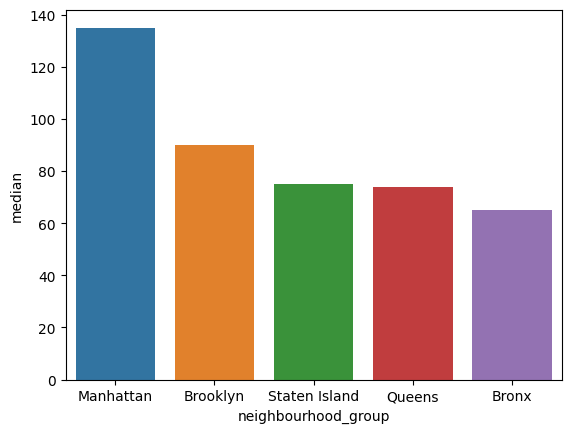

In [33]:
sns.barplot(data=preco_por_regiao, x='neighbourhood_group', y='median', hue='neighbourhood_group')